# 01-C语言核心语法与函数

> 用变量保存数据，用表达式计算结果，用分支和循环组织执行，用函数封装功能。学会这条链，才能逐步读懂单片机的按键、串口、定时器和驱动代码。

这是《嵌入式单片机一套通关》十二篇笔记的第 01 篇，先建立 C 语言基础。本篇以电脑上的标准 C 程序练习语法；指针、数组、结构体和内存管理在第 02 篇展开，GD32 开发环境与工程搭建在第 03 篇展开。


## 1. 本篇范围与资料说明

| 课程分组 | 本篇整理内容 | 学完要能做到 |
|---|---|---|
| 1. Hello C语言 | 编程语言、编译器、IDE、Hello World | 分清写代码、编译和运行 |
| 2. 核心语法 | 注释、变量、类型、常量、进制、字符、输入输出、运算、补码、类型转换 | 判断一段表达式怎样计算、怎样保存结果 |
| 3. 控制语句 | 顺序、分支、循环、跳转 | 根据条件执行，控制循环的次数与退出 |
| 4. 函数 | 定义、调用、参数、返回值、变量作用域、多文件与 extern | 把功能拆成接口和实现 |

**课程来源：**[用户提供的知识库入口](https://www.yuque.com/embheima/mcu)，当前跳转到[嵌入式单片机一套通关](https://www.yuque.com/xxcls/mcu)。本篇已阅读上述四组的 26 个小节中可访问的正文，并核对目录。

**整理方式：**保留课程知识顺序，重新组织解释与示例。本文的代码、算例、练习和自绘图为配套学习补充，不作为课程源码逐字摘录；网页中的图片和附件未逐一下载复刻。

**示例约定：**采用 C99 语法；固定宽度类型以目标工具链提供 `stdint.h` 中对应类型为前提。涉及八位字节、补码、ASCII 的算例会说明假设。已检查笔记文件结构与示例的一致性，未在本环境编译 C 示例或烧录开发板；下文“预期输出”是按代码推导的学习结果。


## 2. C 语言为什么出现在单片机开发里

单片机把处理器、存储器和外设接口集成在芯片中。程序通过指令和外设接口影响电路行为，C 语言则让我们用变量、条件和函数描述这些行为，再由工具链翻译成目标处理器可以执行的机器指令。

| 表达方式 | 人写什么 | 如何交给处理器 |
|---|---|---|
| 机器指令 | 编码后的指令和数据 | 按目标芯片的指令集执行 |
| 汇编语言 | `MOV`、跳转等助记符 | 由汇编器生成目标机器码 |
| C 语言 | 变量、运算、循环、函数 | 由目标工具链编译、汇编和链接 |

课程用点灯帮助理解控制程序，但“写 0 就灭、写 1 就亮”要结合 LED 接线和驱动电路判断。低电平有效的 LED 可能恰好相反，C 语言本身不规定灯的亮灭电平。

一个程序也不能只换文件名就跨芯片运行。电脑上的编译器生成电脑处理器的程序，单片机工具链生成对应芯片的程序；外设寄存器、启动代码和库也要匹配目标。


## 3. 从源代码到可执行程序

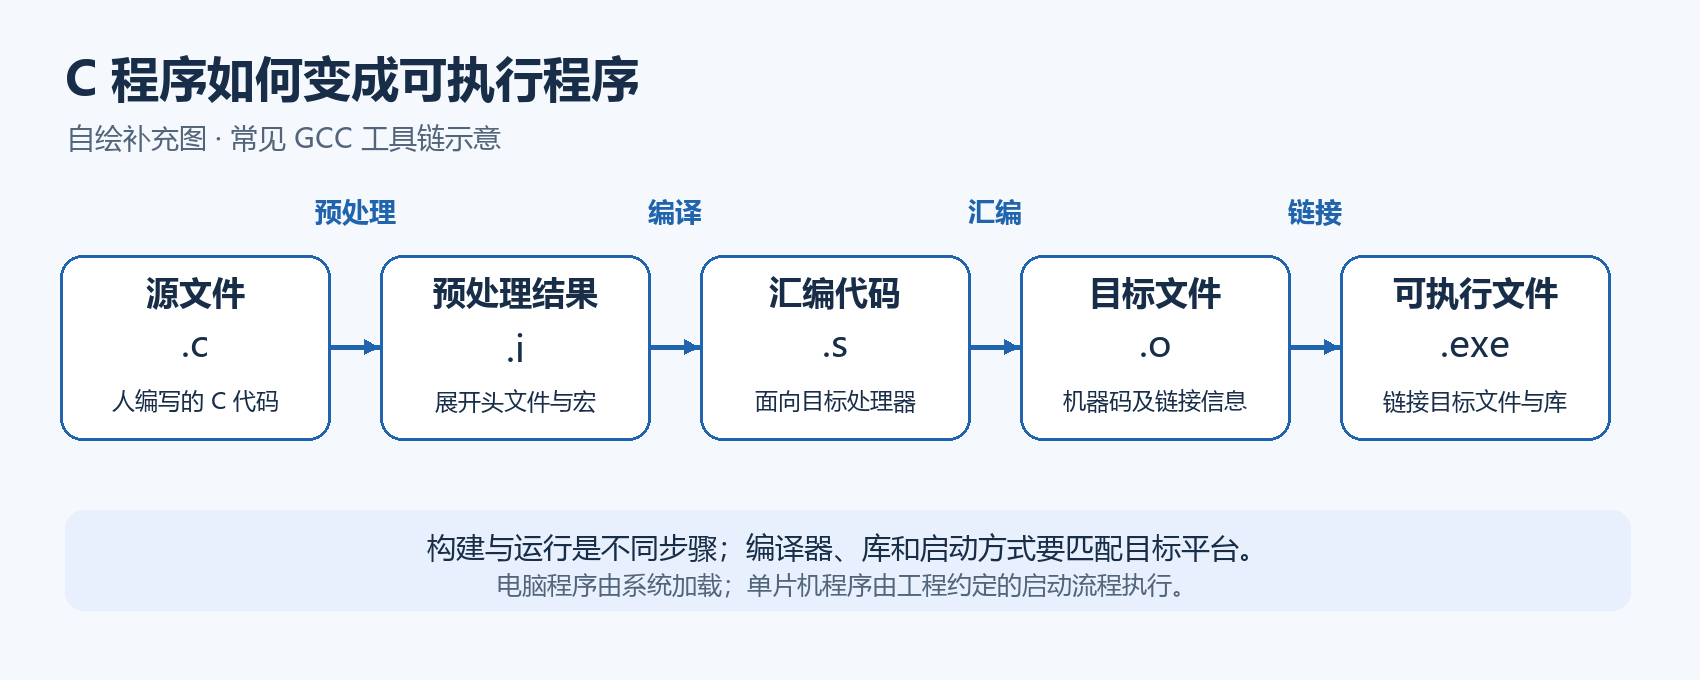

*自绘补充图。扩展名以常见 GCC 工具链为例，实际工具链可能采用不同名称。*

| 阶段 | 主要工作 | 经常遇到的问题 |
|---|---|---|
| 预处理 | 处理 `#include`、`#define`、条件编译 | 头文件找不到、宏写错 |
| 编译 | 分析 C 语法与类型，生成目标代码 | 漏分号、类型冲突、名称未声明 |
| 汇编 | 把汇编代码转换成目标文件 | 目标架构或汇编语法不匹配 |
| 链接 | 组合目标文件与库，解析外部符号 | 函数没有定义、重复定义、缺少库 |
| 运行 | 由电脑系统加载，或由单片机启动流程执行 | 输入不符合预期、逻辑错误、运行环境不匹配 |

**IDE 是开发工作台，编译器是翻译工具。**课程语法阶段使用小熊猫 C++／MinGW，可在 IDE 中编写 C 文件；第 03 篇再学习 Keil 与 GD32。工具名字中有“C++”，不代表当前文件必须写 C++，应保存为 `.c` 并按 C 语言编译。

已有 GCC 时，可以在示例文件所在目录使用：

```text
gcc -std=c99 -Wall -Wextra -Wpedantic -g hello.c -o hello.exe
```

`-std=c99` 选择标准，`-Wall -Wextra -Wpedantic` 提供常用诊断，`-g` 加入调试信息，`-o` 指定输出文件。**源文件由 `hello.c` 这样的参数指定，`-g` 不负责指定源文件。**这些选项帮助发现问题，但不能保证程序逻辑一定正确。

本篇不要求先安装全部工具。先理解构建流程，再用已配置好的学习环境完成语法练习即可。


## 4. 第一个 C 程序及其骨架

```c
#include <stdio.h>

int main(void)
{
    printf("Hello, MCU!\n");
    return 0;
}
```

预期输出：

```text
Hello, MCU!
```

| 写法 | 含义 |
|---|---|
| `#include <stdio.h>` | 包含标准输入输出接口的声明 |
| `int main(void)` | 在本篇电脑程序中，入口函数返回 `int`，不接收参数 |
| `{ ... }` | 代码块，组织语句并形成块作用域 |
| `printf(...)` | 调用标准库函数，向标准输出写入内容 |
| `\n` | 换行字符；和 `\r` 回车字符要区分 |
| `return 0;` | 结束 `main`，在宿主环境中表示成功终止 |

表达式语句、变量声明和 `return` 等通常以分号结束，但不是“所有代码行都加分号”：预处理指令、函数定义和 `if` 的花括号不按这个规则加分号。

单片机通常属于独立式运行环境，先执行启动代码，再进入工程约定的入口。启动、`main` 返回后的行为，以及 `printf` 输出到串口还是调试器，由工具链与工程配置决定。后续 MCU 程序常用无限循环持续工作，不能直接套用电脑程序“执行完就退出”的习惯。


## 5. 注释、命名和基本书写习惯

```c
// 单行注释：说明单位、原因或约束。
int delay_ms = 100;

/* 多行注释可以跨行。
   这种块注释不能直接嵌套同类块注释。 */
int retry_count = 3;
```

`//` 是 C99 支持的写法。旧 C89 工程是否接受它，要看编译器扩展与选项。注释帮助人阅读，不是程序运行时执行的语句。

入门阶段采用英文字母、数字和下划线命名，首字符不写数字。C 区分大小写，`count` 与 `Count` 是两个名字；`int`、`return`、`if` 等关键字不能作为变量名。

| 推荐 | 原因 | 避免 |
|---|---|---|
| `temperature_c` | 含义和单位明确 | `a` 代表温度但没有说明 |
| `delay_ms` | 显示单位是毫秒 | `delay` 的单位不明 |
| `MAX_RETRIES` | 宏名称容易识别 | 把关键字作为名称 |
| `read_button` | 动词说明函数行为 | 数字开头、空格、连字符 |

不要随意使用以下划线开头的名字，尤其 `__name`、`_Name`，以免占用实现保留的标识符。命名风格可以不同，但同一项目应保持一致。

写代码时使用英文半角引号、分号与括号。中文可以出现在注释和合适编码的字符串里，不能把中文引号当作 C 语法中的 `"`。


## 6. 数据类型：宽度、范围与解释方式

在课程使用的电脑平台与常见 ARM 单片机上，通常 `1 byte = 8 bit`。从 C 标准角度，`sizeof(char) == 1` 总是成立，而一个 C 字节有多少位由 `CHAR_BIT` 给出，不应把所有实现都默认成八位字节。

对本篇八位字节、补码模型：

```text
N 位无符号整数：0 ～ 2^N - 1
N 位有符号补码整数：-2^(N-1) ～ 2^(N-1) - 1
```

| 类型 | 常见电脑／ARM 实现 | 应怎样记 |
|---|---|---|
| `char` | 8 bit，可能有符号也可能无符号 | 用于字符；符号属性不要猜 |
| `short` | 通常 16 bit | C 标准不固定它就是 16 bit |
| `int` | 通常 32 bit，某些小型 MCU 是 16 bit | 不能认定所有平台都占 4 字节 |
| `long` | 常见 Windows 为 32 bit，某些 64 位 Unix 为 64 bit | 宽度由工具链的数据模型决定 |
| `long long` | 通常 64 bit | C99 提供，标准要求至少支持 64 位范围 |
| `float` | 常见 IEEE 754 单精度，约 6～7 位十进制有效数字 | 有效数字不是固定小数位数 |
| `double` | 常见 IEEE 754 双精度，约 15～16 位有效数字 | 仍然有舍入与表达范围限制 |
| `bool` | C99 的 `stdbool.h` 提供 | 逻辑值为 0 或 1，存储宽度不固定为 8 bit |

需要明确位宽时，包含 `<stdint.h>`，使用目标实现提供的固定宽度类型：

| 类型 | 位宽 | 范围 |
|---|---:|---|
| `uint8_t` | 8 | 0～255 |
| `int8_t` | 8 | -128～127 |
| `uint16_t` | 16 | 0～65535 |
| `int16_t` | 16 | -32768～32767 |
| `uint32_t` | 32 | 0～4294967295 |
| `int32_t` | 32 | -2147483648～2147483647 |

这些精确宽度类型在能提供对应精确表示的实现上才有定义。课程目标通常提供它们；移植到其他实现时仍需确认。

**选择类型时先想三个问题：要表示负数吗？最大值是多少？数据来自怎样的接口？**例如串口字节用 `uint8_t`，可能为负的温度不要用无符号类型，协议字段或寄存器值则按规定宽度选择。


## 7. 变量的声明、初始化与修改

```c
#include <stdint.h>
#include <stdbool.h>

int temperature_c = 25;        // 定义并初始化
uint16_t adc_value = 2048;
bool fan_on = false;

temperature_c = 30;            // 给已有对象赋新值
fan_on = (temperature_c >= 35);
```

变量有类型、名称和值。类型决定可表示的值和参与运算的方式；名称用来引用这个对象。`=` 把右侧计算结果保存到左侧，不表示数学上的“相等判断”。

```c
int count;       // 在函数内定义的普通局部对象，尚未初始化
count = 0;       // 在读取它之前写入有效值
count += 1;
```

不要读取未初始化的普通局部变量，也不要假设它自动为 0。静态存储期对象的默认初始化规则不同，见第 23 节。

查看当前实现的类型大小：

```c
#include <stdio.h>
#include <limits.h>

int main(void)
{
    printf("CHAR_BIT=%d\n", CHAR_BIT);
    printf("sizeof(int)=%zu bytes\n", sizeof(int));
    printf("sizeof(long)=%zu bytes\n", sizeof(long));
    return 0;
}
```

`sizeof` 的结果是 `size_t`，C99 用 `%zu` 输出。它测量当前实现中的大小，不能用电脑测出的结果替代目标单片机工具链的结果。


## 8. const、宏和预处理

```c
const int alarm_limit_c = 45;
#define MAX_RETRIES 3
#define SAMPLE_PERIOD_MS 100U
```

| 写法 | 本质 | 要注意什么 |
|---|---|---|
| `const int limit = 45;` | 定义一个有类型的只读限定对象 | 不能通过普通赋值修改；不保证一定放在 Flash |
| `#define LIMIT 45` | 在预处理阶段用替换内容展开标记 | 宏本身不是变量，替换结果仍有 C 类型与语义 |

**宏替换发生在编译前的预处理阶段。**运行中的程序不会再执行一次“把宏名替换成值”的操作。`#define` 后面的分号会成为替换内容的一部分，常量宏一般不写它。

C 中的 `const` 对象也不自动等同于所有场景都能使用的整数常量表达式。例如需要 `case` 常量或其他编译期条件时，应按 C 规则选择字面量、适当的宏或枚举常量。

宏表达式要留意括号：

```c
#define SCALE_BAD(x) x * 2
#define SCALE(x) ((x) * 2)

// SCALE_BAD(1 + 2) 展开为 1 + 2 * 2，结果 5。
// SCALE(1 + 2) 展开为 ((1 + 2) * 2)，结果 6。
```

带参数宏还可能重复求值，括号无法解决这个问题：

```c
#define SQUARE(x) ((x) * (x))
// 不要写 SQUARE(i++)：同一个 i 的修改缺少必要的求值顺序。
```

入门时优先用函数封装需要计算的功能。函数参数先得到一个值，函数体不会因为引用同一形参两次就再次计算原实参表达式。


## 9. 进制与数字字面量

进制改变数字的书写方式，不改变数字本身。十进制 168、十六进制 `0xA8` 和八进制 `0250` 表示相同数值。

| 进制 | 基数 | C99 常见写法 | 数值 |
|---|---:|---|---:|
| 十进制 | 10 | `168` | 168 |
| 八进制 | 8 | `0250` | 168 |
| 十六进制 | 16 | `0xA8` | 168 |
| 二进制 | 2 | 本篇用位串 `1010 1000` 说明 | 168 |

`0b10101000` 不是标准 C99 字面量，部分编译器把它作为扩展支持，新标准也有相关支持。本篇 C99 示例使用十六进制，避免依赖扩展。

八位位权由高到低为：

```text
bit 编号：  7    6    5    4    3    2    1    0
位权：     128   64   32   16    8    4    2    1
168：        1    0    1    0    1    0    0    0
168 = 128 + 32 + 8
```

二进制从右向左每四位一组转换成十六进制：`1010 = A`，`1000 = 8`，所以得到 `0xA8`。每三位一组则可转换成八进制。

注意前导零：`010` 在 C 中是八进制，数值为十进制 8；`08` 不是合法的八进制整数。不要给普通十进制整数随意补零。


## 10. 原码、反码与补码：先定宽度和解释方式

课程通过原码、反码、补码解释负数。这里用 **8 bit 补码整数**建立模型，避免把不同编码规则混在一起。

| 数值 | 原码：符号加绝对值 | 反码：负数数值位取反 | 补码 |
|---|---|---|---|
| +5 | `0000 0101` | `0000 0101` | `0000 0101` |
| -5 | `1000 0101` | `1111 1010` | `1111 1011` |
| -1 | `1000 0001` | `1111 1110` | `1111 1111` |

对 -5：先写正数 5 的八位位串 `0000 0101`，**全部取反再加 1**得到 `1111 1011`。也可以先写负数原码，再按表中的反码规则计算。

补码最高位并不是一个完全脱离数值计算的标志。八位补码可以按以下位权解释：

```text
最高位权 = -128，其他位权 = 64、32、16、8、4、2、1。
1111 1011 = -128 + 64 + 32 + 16 + 8 + 2 + 1 = -5。
```

同一组位，解释方式不同，数值就不同：

| 位串 | 作为八位无符号数 | 作为八位有符号补码 |
|---|---:|---:|
| `0111 1111` | 127 | 127 |
| `1000 0000` | 128 | -128 |
| `1111 1111` | 255 | -1 |

`1000 0000` 作为八位补码的 -128 是由位权直接得到的；不能把它说成原码中的负零，然后把负零“临时当成 -128”。八位原码无法表示 -128。

按固定八位模型，`1111 1111 + 0000 0001` 的低八位是 `0000 0000`，帮助理解 -1＋1＝0。但这个位串算例不代表 C 语言允许任意有符号溢出。**C99 中有符号整数溢出是未定义行为，无符号运算才有明确的模运算规则。**

课程的 MinGW 和常见 ARM 平台通常使用补码；C99 本身对一般有符号整数还允许其他表示，移植时应确认目标实现。


## 11. 字符、字符串与布尔值

```c
char command = 'A';
int count = 1;
char digit = '1';
```

在 ASCII 兼容环境中，`'A'` 编码为 65，`'1'` 编码为 49。字符 `'1'` 与整数 `1` 不相同。在 C 中，普通字符常量如 `'A'` 的类型是 `int`，它可以赋给能表示该编码的 `char` 对象。

| 写法 | 含义 |
|---|---|
| `'A'` | 字符常量 |
| `"A"` | 字符串字面量，含 `'A'` 与结束符 `\0` |
| `'0'` | 字符 0，ASCII 编码 48 |
| `'\0'` | 数值为 0 的空字符，常作字符串结束标志 |
| `'\n'` | 换行字符 |
| `'\t'` | 水平制表符 |
| `'\\'` | 反斜杠字符 |

字符串用双引号包围，在存储表示上是一串字符并带结束标志。中文通常涉及多字节编码，不能认为一个中文字符一定对应一个 `char`。字符串存储与数组操作在第 02 篇进一步学习。

```c
#include <stdio.h>
#include <stdbool.h>

int main(void)
{
    char command = 'A';
    bool ready = true;
    printf("char=%c, code=%d, ready=%d\n",
           command, (int)command, ready);
    return 0;
}
```

在 ASCII 兼容环境中的预期输出：

```text
char=A, code=65, ready=1
```

条件判断中，0 为假，非 0 为真；比较和逻辑运算的结果是 `int` 类型的 0 或 1。赋值到 C99 的 `bool` 时，也会归一化为 0 或 1。


## 12. printf：格式与参数必须匹配

```c
#include <stdio.h>
#include <stdint.h>
#include <inttypes.h>

int main(void)
{
    int temperature_c = 26;
    unsigned int flags = 5U;
    double voltage = 3.3;
    uint32_t ticks = UINT32_C(1000);

    printf("temp=%d C, flags=0x%X\n", temperature_c, flags);
    printf("voltage=%.2f V\n", voltage);
    printf("ticks=%" PRIu32 "\n", ticks);
    return 0;
}
```

预期输出：

```text
temp=26 C, flags=0x5
voltage=3.30 V
ticks=1000
```

| `printf` 格式 | 对应参数 |
|---|---|
| `%d` | `int` |
| `%u` | `unsigned int` |
| `%ld`、`%lu` | `long`、`unsigned long` |
| `%lld`、`%llu` | `long long`、`unsigned long long` |
| `%x`、`%X`、`%o` | `unsigned int`，分别按十六／八进制输出 |
| `%c` | 经过整数提升的字符值 |
| `%s` | 指向以空字符结束的有效字符序列 |
| `%f`、`%.2f` | `double`；`float` 传入可变参数时提升为 `double` |
| `%zu` | `size_t`，例如 `sizeof` 的结果 |
| `%%` | 输出一个 `%`，不消耗额外参数 |

输出固定宽度整数，优先使用 `<inttypes.h>` 的 `PRIu32` 等宏，或显式转换到匹配的已知类型。不要只因为 `uint32_t` 是 32 位，就假定它在所有实现上一定等于 `unsigned int`。

在 C99 的 **printf** 中，`%f` 可同时用于传入的 `float` 和 `double`；`%lf` 中的 `l` 对浮点输出没有额外作用。`long double` 使用 `%Lf`。不要把这里的规则直接套给 `scanf`。

`%10.2f` 中的 10 是最小字段宽度，2 是小数点后输出位数；实际输出更长时不会按 10 截断。`%.2f` 调整显示格式，不会提高原值的计算精度。

格式或参数数量不匹配可能产生未定义行为，不能当成可靠的类型转换方法。单片机上的 `printf` 还需要输出通道配置，且可能增加代码体积，第 06 篇再结合串口学习。


## 13. 输入：scanf 与 getchar

```c
#include <stdio.h>

int main(void)
{
    int temperature_c = 0;
    double voltage = 0.0;

    if (scanf("%d %lf", &temperature_c, &voltage) != 2) {
        printf("input error\n");
        return 1;
    }

    printf("temp=%d, voltage=%.2f\n", temperature_c, voltage);
    return 0;
}
```

输入 `25 3.3` 时，预期输出 `temp=25, voltage=3.30`。这里的 `&` 取得变量地址，让函数能把输入写到对象中；指针机制在第 02 篇详细解释。

| 要读取的对象 | `scanf` 格式 | 传入形式 |
|---|---|---|
| `int` | `%d` | `&value` |
| `unsigned int` | `%u` | `&value` |
| `float` | `%f` | `&value` |
| `double` | `%lf` | `&value` |
| `char` | `%c` 或 ` %c` | `&value` |

**scanf 的 `%f` 要 `float` 的地址，`%lf` 要 `double` 的地址；printf 的浮点参数规则不同。**

`scanf` 返回成功赋值的项目数，出现输入结束或错误且未转换时可能返回 `EOF`。读取两个值就应检查是否返回 2。`%c` 不自动跳过空白，`" %c"` 中的前导空格会跳过包括换行在内的空白，适合读取一个非空白命令字符。

读取单个字符并检测输入结束：

```c
int ch = getchar();
if (ch != EOF) {
    printf("char=%c\n", ch);
}
```

使用 `int` 保存 `getchar()` 的返回值，才能保留普通字符与 `EOF` 的区别。不要先存成 `char` 再判断。

本节 `scanf` 是受控的入门练习：仅检查返回值不能妥善处理所有越界数值与错误行。真实输入通常要读入一行，再用 `strtol` 等函数检查范围与尾部内容；这需要第 02 篇的数组和指针知识。此处不使用无宽度限制的 `%s`。


## 14. 算术运算与赋值

| 运算符 | 含义 | 示例结果 |
|---|---|---|
| `+ - *` | 加、减、乘 | `10 + 3` 为 13 |
| `/` | 除法 | `10 / 3` 为 3；`10.0 / 3` 为浮点结果 |
| `%` | 整数求余 | `10 % 3` 为 1 |
| `+= -= *= /= %=` | 运算后赋值 | 对简单变量，`x += 2` 相当于 `x = x + 2` |
| `++ --` | 自增、自减 | 作为独立语句时，`++x;` 与 `x++;` 都使 x 加 1 |

整数除法向 0 截断，C99 中 `-7 / 3` 为 -2，`-7 % 3` 为 -1。除数不能为 0；有符号最小值除以 -1 也可能超出可表示范围。

```c
int a = 2;
int before = a++;    // before = 2，随后 a = 3

int b = 2;
int after = ++b;     // 先让 b = 3，再让 after = 3
```

初学时把自增写成独立语句，少在复杂表达式里混用。不要写 `i = i++`、`i++ + i++` 等对同一个对象缺少必要求值顺序的修改。

```c
double wrong = 5 / 2;           // 先按整数算出 2，再转换为 2.0
double correct = (double)5 / 2; // 参与除法时已是浮点，得到 2.5
```

**结果保存到 double，并不会让已经完成的整数除法重新变成浮点除法。**同理，把已经溢出的中间结果强转成大类型也无法补救。


## 15. 比较、逻辑运算与求值规则

| 比较 | 含义 | 逻辑 | 含义 |
|---|---|---|---|
| `==`、`!=` | 相等、不等 | `!` | 逻辑非 |
| `<`、`<=` | 小于、小于等于 | `&&` | 两边都为真 |
| `>`、`>=` | 大于、大于等于 | `||` | 至少一边为真 |

```c
bool in_range = (temperature_c >= -40) && (temperature_c <= 125);
```

不要写 `-40 <= temperature_c <= 125`。C 会先计算左边比较，得到 0 或 1，再用这个结果与 125 比较，与数学上的连续不等式含义不同。

`&&` 和 `||` 有从左向右的短路规则：

```c
if ((divisor != 0) && (value / divisor > 3)) {
    // divisor 为 0 时，右边不计算，因此不会执行除以 0。
}
```

按位 `&`、`|` 没有这样的短路语义，也不是逻辑运算的同义替换。`2 && 1` 为 1，`2 & 1` 为 0。

注意三个独立问题：

- **优先级**决定表达式如何分组，例如乘法比加法先结合。
- **结合性**决定同级运算怎样分组，不保证各子表达式的执行先后。
- **求值顺序**决定什么时候计算操作数；C 不普遍保证从左到右，例如函数实参的求值顺序不固定。

所以在不确定分组时加括号，在有副作用时拆成独立语句。`printf("%d %d", i++, i++)` 不能用“参数从左到右对应”来推断安全结果。


## 16. 位运算：单片机代码的常用工具

位运算对整数的各个位操作。以下位串用四位宽度帮助说明，真实 C 表达式还受类型宽度和整数提升影响。

| 运算符 | 规则 | 位串示例 |
|---|---|---|
| `&` | 两位均为 1 才为 1 | `0011 & 0101 = 0001` |
| `|` | 至少一位为 1 就为 1 | `0011 | 0101 = 0111` |
| `^` | 两位不同为 1 | `0011 ^ 0101 = 0110` |
| `~` | 对参与运算类型的所有位取反 | 四位模型中 `~0011 = 1100` |
| `<<` | 左移，低位补 0 | `3U << 1` 为 6 |
| `>>` | 无符号数右移，高位补 0 | `10U >> 1` 为 5 |

用一个普通软件变量模拟状态位：

```c
#include <stdint.h>
#include <stdbool.h>

uint32_t flags = UINT32_C(0);
const uint32_t alarm_mask = UINT32_C(1) << 3;

flags |= alarm_mask;                 // 置 bit3，其他位不变
flags &= ~alarm_mask;                // 清 bit3，其他位不变
flags ^= alarm_mask;                 // 翻转 bit3
bool alarm_on = (flags & alarm_mask) != 0;
```

| 目的 | 常见形式 |
|---|---|
| 把某些位设为 1 | `value |= mask` |
| 把某些位清为 0 | `value &= ~mask` |
| 翻转某些位 | `value ^= mask` |
| 判断任一目标位为 1 | `(value & mask) != 0` |
| 判断所有目标位为 1 | `(value & mask) == mask` |

位测试的括号不能省略为 `flags & mask == mask`，因为 `==` 比 `&` 优先级高，会产生不同的分组。

### 八位变量不代表一定以八位执行表达式

```c
uint8_t x = 5;
uint8_t inverse = (uint8_t)~x;  // 在提供 uint8_t 的模型中，保存结果为 250

uint8_t y = 41;
unsigned int wide = (unsigned int)y << 4; // 656
uint8_t narrow = (uint8_t)wide;            // 144
```

小整数参与运算时常先提升为 `int`。不能直接认定 `~x` 的表达式结果就是八位无符号 250；在常见补码实现中，提升后的 `~5` 是 `int` 值 -6，再转换到 `uint8_t` 才得到 250。`41 << 4` 也不会因为原变量是八位而自动在八位截断，保存到窄类型是后续步骤。

移位数量必须非负，且小于**提升后左操作数类型**的位宽。C99 的负有符号数右移由实现定义，负数左移或某些有符号左移溢出则属于未定义行为。表达位掩码时优先用适当宽度的无符号值，并确认移位范围。

本节操作的是普通变量。硬件寄存器可能有“写 1 清零”、只写、保留位以及并发访问等规则，不能把所有 `|=`、`&=` 无条件套到真实寄存器上；第 04 篇再结合手册学习。


## 17. 类型转换：转换不等于数值永远安全

| 发生位置 | 例子 | 核心问题 |
|---|---|---|
| 小整数参加运算 | `uint8_t` 参与 `+`、`~` | 先做整数提升 |
| 不同类型混合 | 有符号数与无符号数比较 | 运算前会按规则转换 |
| 赋值或返回 | 把较宽结果存入较窄类型 | 是否丢失范围或精度 |
| 显式转换 | `(uint8_t)value` | 转换动作明确，仍不代替范围检查 |

不能只记“字节少的自动转成字节多的”。类型的等级、范围、符号以及运算类别共同决定规则。

```c
uint16_t raw = 300;
uint8_t low = (uint8_t)raw;       // 300 mod 256 = 44

double value = 3.9;
int integer = (int)value;        // 在范围内时，向 0 截断，结果 3
```

转换到无符号类型有模规则；转换到不能表示该值的有符号整数，在 C99 中可能得到由实现定义的结果或信号，不能统一说“自然截断成某个负数”。浮点数转整数还必须保证整数部分可表示。

如果业务要求 0～255，就先验证，不应把 300 截成 44 后再称它是有效输入：

```c
int requested = 300;
if ((requested >= 0) && (requested <= 255)) {
    uint8_t accepted = (uint8_t)requested;
    // 在这个分支内使用 accepted。
}
```

先扩大参与运算的类型，避免中间结果不够宽：

```c
uint16_t a = 60000;
uint16_t b = 2;
uint32_t product = (uint32_t)a * b;  // 先让乘法在足够宽的类型中进行，结果 120000
```

常见 32 位 `unsigned int` 环境里，`-1 < 1U` 是假，因为 -1 会按规则转换为无符号值。其他数据模型可能有不同转换路径，处理混合符号数据时应先梳理范围，不能凭直觉比较。


## 18. 分支：if、else if、switch 与条件表达式

### 根据区间选择行为

```c
if (temperature_c >= 45) {
    printf("ALARM\n");
} else if (temperature_c >= 35) {
    printf("COOLING\n");
} else {
    printf("IDLE\n");
}
```

这是一条互斥分支链，只执行第一个满足条件的分支。先判断较高阈值，否则 45 可能已经被 `>= 35` 的分支截获。

| 温度 | 结果 |
|---:|---|
| 34 | IDLE |
| 35 | COOLING |
| 44 | COOLING |
| 45 | ALARM |

独立的多个 `if` 可以分别成立，适合多个互不排斥的动作；`else if` 表示在一组选择中选一个。

### 根据离散值选择行为

```c
switch (command) {
case '1':
    printf("START\n");
    break;
case '0':
    printf("STOP\n");
    break;
default:
    printf("UNKNOWN\n");
    break;
}
```

`switch` 根据整数类表达式选择 `case`，普通 `case` 标签需要整数常量表达式。省略 `break` 时会继续执行后续标签处的语句，只有确实需要这种行为时才有意保留并说明。

简单选值可写条件表达式：

```c
int larger = (a > b) ? a : b;
```

条件成立只计算被选择的这一侧表达式。复杂动作用清晰的 `if` 组织，不必堆叠多层条件表达式。

常见错误：`if (x = 1)` 是赋值而非比较；`if (ready);` 中的分号是空语句，使后面的代码块不再受这个 `if` 控制。


## 19. 循环：每一轮到底按什么顺序执行

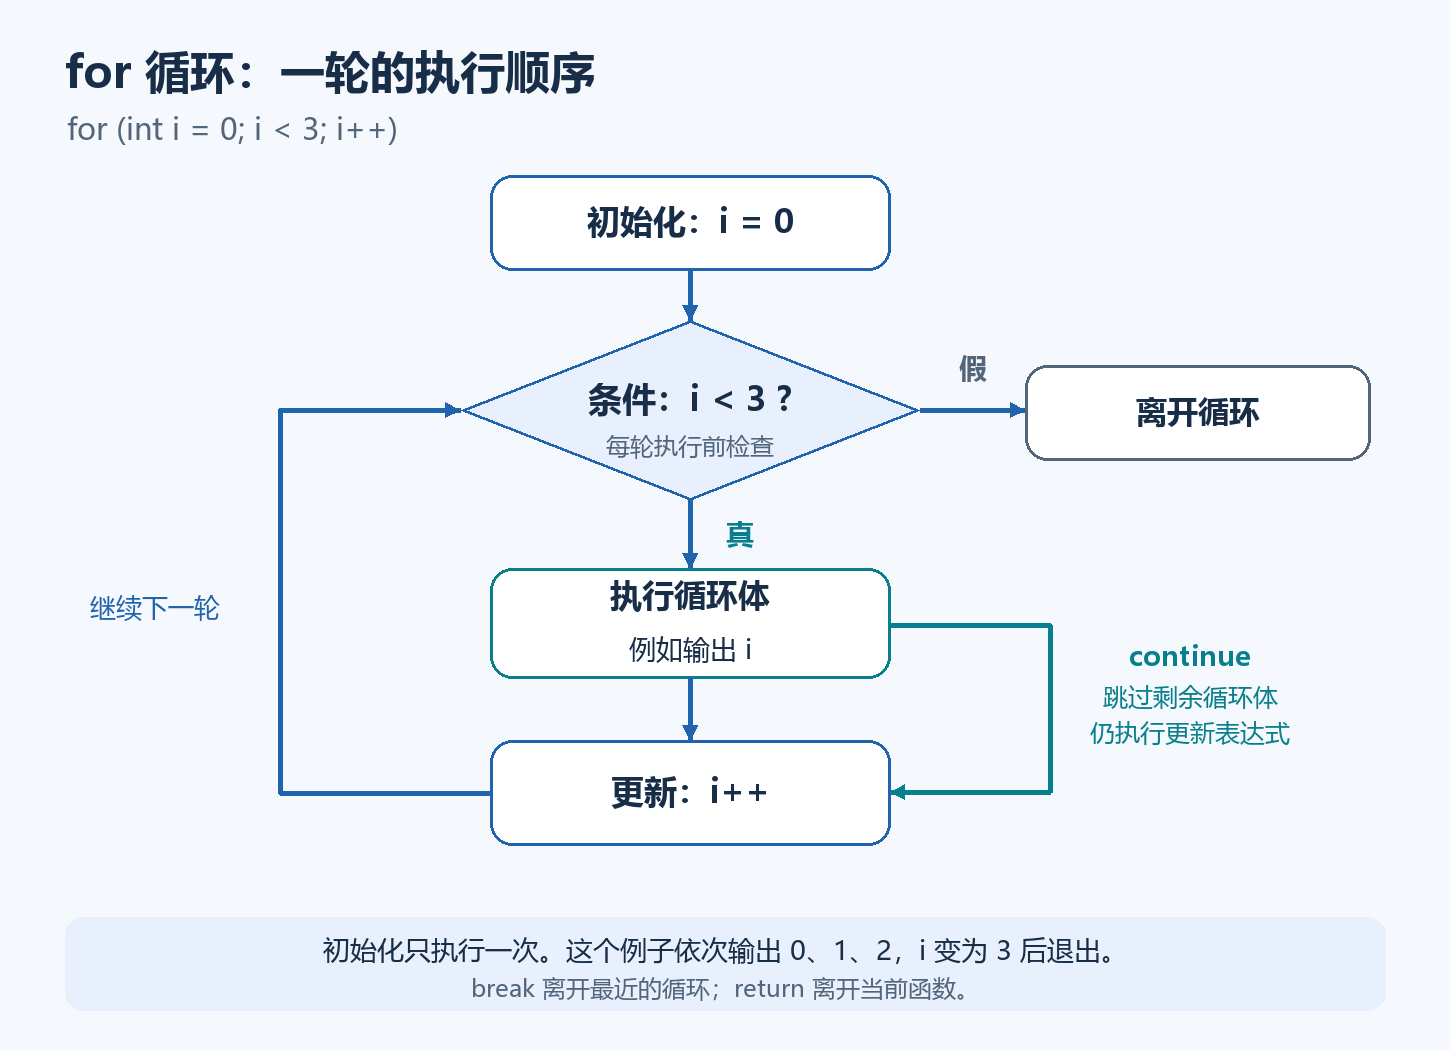

*自绘补充图，展示本篇有限次数循环的控制路径。*

| 循环 | 执行特征 | 适合场景 |
|---|---|---|
| `while` | 先检查条件，可以一次也不执行 | 次数未定，条件决定是否继续 |
| `do ... while` | 先执行一次，再检查条件 | 菜单或操作需要至少执行一次 |
| `for` | 初始化、条件、更新集中书写 | 已知次数或明确的计数规则 |

```c
int count = 0;
while (count < 3) {
    printf("count=%d\n", count);
    count++;
}
```

```c
int count = 0;
do {
    printf("count=%d\n", count);
    count++;
} while (count < 3);  // do ... while 的结尾需要这个分号
```

```c
for (int count = 0; count < 3; count++) {
    printf("count=%d\n", count);
}
```

三例的预期输出均为 0、1、2。`for` 的初始化只执行一次；每轮检查条件，通过后执行循环体，再执行更新。循环变量若在 `for` 初始化部分声明，其作用域覆盖这个 `for`，不是整个函数。

从 0 开始循环 n 次，通常使用 `i < n`；从 1 开始循环到 n，通常使用 `i <= n`。判断边界前先确定起点、目标次数和变量范围。


## 20. 循环练习、跳转与无限循环

累加 1～100：

```c
int sum = 0;
for (int i = 1; i <= 100; i++) {
    sum += i;
}
// 预期 sum = 5050。
```

求 5～20 范围内的偶数之和：

```c
int sum = 0;
for (int i = 5; i <= 20; i++) {
    if (i % 2 != 0) {
        continue;
    }
    sum += i;
}
// 预期 sum = 104。
```

| 关键字 | 作用 | 容易混淆的边界 |
|---|---|---|
| `break` | 退出最近一层循环或 `switch` | 不能直接退出所有嵌套层，也不是退出函数 |
| `continue` | 结束本轮循环体 | `for` 转到更新表达式；`while` 转到条件判断 |
| `return` | 结束当前函数 | 即使写在循环里，也会离开整个函数 |
| `goto label` | 跳到同一个函数中的标签 | 不是任意跨函数跳转；入门先用结构化流程 |

嵌套循环里，一个 `break` 只作用于最近的循环／`switch`。`continue` 也可用于 `do ... while`，其下一步是检查条件。

### 两类常见死循环

```c
int i = 0;
while (i < 3) {
    if (i == 1) {
        continue;  // 错误示例：跳过 i++，此后一直停在 i == 1
    }
    i++;
}
```

```c
// 错误示例：uint8_t 最大为 255，更新后回绕到 0。
// for (uint8_t i = 0; i <= 255; i++) { ... }
```

遍历 256 个值应使用能表示退出边界的计数类型，例如 `for (unsigned int i = 0; i < 256U; i++)`。

### 单片机主循环为什么可以无限

```c
while (1) {
    // 检查输入、更新状态、处理输出。
}
```

设备通常需要持续服务，所以无限主循环有明确用途。有限循环写错而无法退出，和有意维持设备运行，是两种情况。循环执行次数也不直接等于毫秒延时：时钟、编译优化和每轮指令数都会影响耗时，定时器将在第 05 篇学习。


## 21. 函数：声明、定义与调用

函数把一个明确功能封装成可调用单元。**声明说明接口，定义给出实现，调用让程序执行这个功能。**

```c
int max_value(int a, int b);   // 声明：以分号结束

int main(void)
{
    int result = max_value(10, 20); // 调用
    return (result == 20) ? 0 : 1;
}

int max_value(int a, int b)    // 定义：有函数体
{
    return (a > b) ? a : b;
}
```

函数定义在调用前时，定义本身也能提供声明；定义放在调用后或其他文件时，调用前应提供匹配的函数声明。头文件通常承担这件事。

| 类型 | 示例接口 | 典型用途 |
|---|---|---|
| 无参、无返回值 | `void print_menu(void)` | 输出菜单或执行动作 |
| 有参、无返回值 | `void print_value(int value)` | 使用输入执行动作 |
| 无参、有返回值 | `int get_default_limit(void)` | 返回默认配置 |
| 有参、有返回值 | `int max_value(int a, int b)` | 计算并返回结果 |

在 C99 的函数声明中，`f(void)` 明确表示无参数，`f()` 不提供参数类型信息。初学时统一使用 `void` 明确无参数。`void` 返回类型表示没有返回值，不表示没有功能。

普通调用需要匹配接口：实参数量、类型、返回值用途都要合理。函数不会因为“名字像某个功能”就自动被调用；启动入口、中断或回调等特殊调用路径要按实际工程理解。


## 22. 参数按值传递，return 把结果交回调用者

```c
void change_copy(int value)
{
    value = 99;
}

int add_offset(int value, int offset)
{
    return value + offset;
}

int main(void)
{
    int temperature_c = 25;
    change_copy(temperature_c);
    // temperature_c 仍为 25，change_copy 改的是形参对象。

    int adjusted = add_offset(temperature_c, 2);
    // adjusted 为 27，temperature_c 仍为 25。
    temperature_c = adjusted;
    // 这里显式赋值后，temperature_c 才变为 27。
    return 0;
}
```

调用时，实际参数的值用于初始化形参。函数内部的普通形参是函数自己的对象。要通过函数改动调用者对象，需要适当的指针接口，第 02 篇继续学习；传入指针时，指针值本身也仍是按值传递。

位置关系是第一个实参对应第一个形参、第二个对应第二个，但这**不保证实参表达式从左到右求值**。有相互依赖的计算应先完成，再把结果传入函数。

`return` 一执行就结束当前函数：

```c
bool valid_temperature(int value)
{
    if (value < -40) {
        return false;
    }
    if (value > 125) {
        return false;
    }
    return true;
}
```

上例需要先包含 `<stdbool.h>`。非 `void` 函数应在需要返回结果的所有执行路径上返回合适的值，不要让调用者使用不存在的结果。`void` 函数可以用 `return;` 提前结束。

为函数写清输入范围也很重要：例如两个 `int` 相加若可能溢出，不能只写一个 `return a + b;` 就认为所有输入都有效。本节调用使用小范围值，真实接口还应规定范围或错误反馈。


## 23. 作用域、生命周期与 static

“在哪能看到名称”与“对象能存在多久”是两个问题；跨文件还要区分“这个名称是否链接到同一个对象”。

| 定义位置或方式 | 名称作用范围 | 对象生命周期／链接 |
|---|---|---|
| 块内普通局部变量 | 从声明处到所属块结束 | 通常为自动存储期 |
| 函数形参 | 函数体内 | 随这次调用存在 |
| 块内 `static` 变量 | 仍是局部名称 | 静态存储期，跨调用保留值 |
| 文件作用域普通变量 | 从声明处到该文件相关范围结束 | 静态存储期，通常具有外部链接 |
| 文件作用域 `static` 变量／函数 | 当前翻译单元内使用 | 内部链接，不供其他文件用 extern 访问 |

```c
int global_count;            // 未显式初始化：静态存储期对象默认初始化为 0
static int internal_count;   // 当前文件内部使用

int next_sequence(void)
{
    static int sequence = 0; // 只初始化一次，不是每次调用重新置 0
    sequence++;
    return sequence;
}
```

在调用次数未超过 `int` 可表示范围的前提下，连续两次调用 `next_sequence()` 返回 1、2。这个静态局部对象一直存在，但它的名称只能在函数中相应作用域使用。

全局变量不是“所有源文件无需声明就能看到”。其他文件要有适当的声明，链接器再把具有外部链接的符号对应起来。全局变量共享得越多，依赖越难追踪，优先使用参数、返回值以及清楚的模块接口。

`volatile` 在后续硬件访问与中断中会出现。本篇先记住：它与 `const` 含义不同，也不自动提供原子性、互斥或线程安全；不能把它当作所有共享数据问题的解决办法。


## 24. 多文件编程：头文件声明，源文件实现

下面是**可保存为三个独立 C／头文件的补充示例**。此处用 `extern` 展示跨文件对象声明，尚未连接任何真实硬件。

### control.h

```c
#ifndef MCU_CONTROL_H
#define MCU_CONTROL_H

int classify_temperature(int temperature_c);
extern unsigned int decision_count;

#endif
```

### control.c

```c
#include "control.h"

unsigned int decision_count = 0U; // 整个程序只在这里定义一次

int classify_temperature(int temperature_c)
{
    decision_count++;
    if ((temperature_c < -40) || (temperature_c > 125)) {
        return -1;
    }
    if (temperature_c >= 45) {
        return 2;
    }
    if (temperature_c >= 35) {
        return 1;
    }
    return 0;
}
```

### main.c

```c
#include <stdio.h>
#include "control.h"

int main(void)
{
    int mode = classify_temperature(40);
    printf("mode=%d, decisions=%u\n", mode, decision_count);
    return 0;
}
```

预期输出：`mode=1, decisions=1`。

已有 GCC 时，在三个文件所在目录构建：

```text
gcc -std=c99 -Wall -Wextra -Wpedantic -g main.c control.c -o main.exe
```

| 机制 | 作用 |
|---|---|
| `#include "control.h"` | 为使用者提供声明；引用头文件不等于编译进 `control.c` 的实现 |
| 头文件保护宏 | 防止同一翻译单元中重复展开头文件内容 |
| `extern unsigned int decision_count;` | 声明外部链接对象，本例不创建新的定义 |
| `unsigned int decision_count = 0U;` | 在一个源文件中给出对象定义 |
| 同时编译两个 `.c` | 使链接器能获得函数实现与对象定义 |

不要把 `unsigned int decision_count = 0U;` 放进会被多个 `.c` 包含的头文件，否则容易出现重复定义。头文件保护只能阻止同一翻译单元的重复包含，不能阻止多个翻译单元各自生成一份定义。

`extern` 并不强制定义一定来自另一个文件，重点是声明与链接关系；带初始化的 `extern` 也可能是定义。这里采用“头文件 extern 声明，一个 `.c` 定义”的清晰写法。

`<...>` 通常用于系统头文件，`"..."` 常用于项目头文件，具体搜索目录由实现及 `-I` 等选项决定。不要 `#include "control.c"` 来代替正常的多文件构建。


## 25. 综合示例：温度判断与状态位

把变量、输入、范围检查、分支、循环、函数和位操作串在一起。下面是一个**独立的电脑端语法练习**，与上一节的三个文件示例分开保存；状态位用普通变量模拟，没有实际驱动风扇或读取传感器。

约定：有效输入为 -40～125℃；35℃开始散热；45℃开始报警并散热。bit0 表示散热，bit1 表示报警。一次处理 5 个整数输入，输入格式错误就结束；超出业务范围的值跳过。

```c
#include <stdio.h>
#include <stdint.h>
#include <inttypes.h>

#define FAN_MASK   (UINT32_C(1) << 0)
#define ALARM_MASK (UINT32_C(1) << 1)

int classify_temperature(int temperature_c);

int main(void)
{
    unsigned int valid_count = 0U;

    for (int sample = 0; sample < 5; sample++) {
        int temperature_c = 0;
        uint32_t flags = UINT32_C(0); // 每个样本重新生成状态

        if (scanf("%d", &temperature_c) != 1) {
            printf("input error\n");
            return 1;
        }

        int mode = classify_temperature(temperature_c);
        if (mode < 0) {
            printf("invalid: %d\n", temperature_c);
            continue;
        }

        valid_count++;
        switch (mode) {
        case 2:
            flags |= FAN_MASK | ALARM_MASK;
            break;
        case 1:
            flags |= FAN_MASK;
            break;
        default:
            break;
        }

        printf("temp=%d, mode=%d, flags=0x%" PRIX32 "\n",
               temperature_c, mode, flags);
    }

    printf("valid=%u\n", valid_count);
    return 0;
}

int classify_temperature(int temperature_c)
{
    if ((temperature_c < -40) || (temperature_c > 125)) {
        return -1;
    }
    if (temperature_c >= 45) {
        return 2;
    }
    if (temperature_c >= 35) {
        return 1;
    }
    return 0;
}
```

依次输入下面五个受控整数：

```text
-50 25 35 45 34
```

按代码推导的预期输出：

```text
invalid: -50
temp=25, mode=0, flags=0x0
temp=35, mode=1, flags=0x1
temp=45, mode=2, flags=0x3
temp=34, mode=0, flags=0x0
valid=4
```

| 关键设计 | 原因 |
|---|---|
| 函数先检查范围 | 非法值不会继续参与业务判断 |
| 高阈值先判断 | 45℃进入报警状态 |
| `continue` 跳过无效样本 | `for` 仍执行更新，不会停在同一轮 |
| `flags` 在循环体内初始化 | 新样本不会继承上一轮的报警位 |
| 先声明函数接口 | `main` 调用时编译器知道参数与返回类型 |

这是阈值判断模型，尚未处理真实温度的抖动、回差、传感器故障和实时性。后续学习 ADC 与传感器时，再把“输入数据”替换为真实采集接口。


## 26. 常见错误与排查顺序

| 现象或写法 | 原因 | 怎样检查 |
|---|---|---|
| `.cpp` 中练习 C99 却表现不同 | 按 C++ 规则编译了 | 文件类型与编译语言 |
| `if (ready);` 后的块总执行 | 条件后多了空语句 | 分号与花括号 |
| `if (value = 1)` | 把赋值写成比较 | 应使用 `==` 的位置 |
| `double x = 5 / 2;` 得到 2.0 | 除法先按整数完成 | 运算发生时的类型 |
| 负温度变成很大的数 | 无符号类型或混合符号转换 | 输入范围与转换规则 |
| `~uint8_t` 的打印不像八位取反 | 参与运算前整数提升 | 表达式类型与最终保存类型 |
| `flags & mask == mask` 判断不对 | 优先级造成不同分组 | 写成 `(flags & mask) == mask` |
| `scanf` 后读取不到期望的字符 | `%c` 读到了残留空白 | 是否需要 `" %c"` |
| 输入错误后变量不符合预期 | 没检查转换是否成功 | `scanf` 返回值与输入范围 |
| `printf` 数值乱码 | 格式与参数不匹配 | 类型、数量与顺序 |
| `while` 一直不退出 | 更新缺失或被 continue 跳过 | 每条路径是否推进状态 |
| 八位计数器无法结束 256 次循环 | 达到 255 后回绕 | 退出边界是否能表示 |
| undefined reference／未定义符号 | 有声明，没有链接进定义 | 对应 `.c` 或库是否参加构建 |
| multiple definition／重复定义 | 同一外部对象或函数定义多次 | 头文件是否放了普通定义 |
| 每次调用静态局部计数都想从 0 开始 | 把 static 生命周期理解错了 | 是否应改为普通局部变量 |

排查时依次看：**编译语言与诊断 → 声明和类型 → 表达式实际分组 → 分支与循环路径 → 链接文件 → 输入与预期结果**。如果问题只出现在单片机上，再检查目标配置、启动与硬件接口。


## 27. 自测与练习

先不运行，写出结果及理由，再在已配置的 C 环境中对照。

### 自测题

1. `010`、`0x10`、`10` 分别是多少？
2. `double x = 7 / 2;` 与 `double y = 7 / 2.0;` 的值分别是多少？
3. `uint8_t x = 5; uint8_t y = (uint8_t)~x;` 中 y 是多少？能否据此说 `~x` 也是 `uint8_t`？
4. `2 && 1` 与 `2 & 1` 分别得到什么？
5. `flags = 0xA8`，执行 `flags |= 1U << 2`、再 `flags &= ~(1U << 3)` 后，低八位是多少？
6. `for` 循环执行 `continue` 后，会不会跳过更新表达式？
7. `void change(int value) { value = 99; }` 能否改变调用者传入的普通 int 对象？
8. 头文件保护能否解决“两个 `.c` 都定义了同一个全局变量”的问题？
9. 读取 `double voltage` 时，`scanf` 应写 `%f` 还是 `%lf`？输出它又应怎样写？

### 参考答案

1. 分别为 8、16、10。
2. x＝3.0，y＝3.5；第一式先做整数除法。
3. y＝250；不能，小整数通常先提升为 int，显式转换才产生八位保存结果。
4. 分别为 1 和 0，逻辑判断与逐位计算不同。
5. `0xA8 → 0xAC → 0xA4`，十进制 164。
6. 不会；`for` 的 continue 转到更新表达式，再检查条件。
7. 不能；修改的是形参，普通值传递不改调用者对象。
8. 不能；保护宏只限制同一个翻译单元内的重复包含。
9. 输入用 `scanf("%lf", &voltage)` 并检查返回值；输出可用 `printf("%.2f", voltage)`。

### 编程练习

| 练习 | 验收条件 | 提示 |
|---|---|---|
| 返回三个整数中的最大值 | `(3, 9, 4)` 得 9；`(-5, -2, -9)` 得 -2；相等值正确 | 用函数返回，不在函数内只打印 |
| 求 1～n 的和，约定 0≤n≤100 | n＝0 得 0；n＝1 得 1；n＝100 得 5050；非法 n 有反馈 | 检查参数，再循环 |
| 修改温度示例阈值 | 34、35、44、45 的结果与规则一致 | 注意 else if 的排列 |
| 把分类函数拆成 `.h` 与 `.c` | main 只包含头文件；实现文件参加构建 | 不要包含 `.c` |

前三个数最大值的参考实现：

```c
int max3(int a, int b, int c)
{
    int result = a;
    if (b > result) {
        result = b;
    }
    if (c > result) {
        result = c;
    }
    return result;
}
```

此函数只比较和赋值，没有求和溢出问题，负数与相等值也适用。


## 28. 一页复习与十二篇学习路线

| 知识点 | 本篇要记住的规则 |
|---|---|
| 编译过程 | 预处理、编译、汇编、链接各有职责，运行是后续步骤 |
| 类型 | 位宽和符号要确认，固定宽度类型能明确接口要求 |
| 变量 | 使用前声明，普通局部对象读取前初始化 |
| 宏 | 编译前展开，括号不能消除重复求值问题 |
| 补码 | 先确定宽度与表示法，同一组位可解释成不同值 |
| 字符 | `'1'` 与 1 不同，`'\0'` 与 `'0'` 不同 |
| 输入输出 | 参数与格式匹配；printf 与 scanf 浮点规则不同 |
| 运算 | 整数除法先发生，保存类型不会反向改变它 |
| 位运算 | 看整数提升、移位宽度和掩码；逻辑运算另有规则 |
| 转换 | 强制转换不代替范围检查 |
| 流程 | 分支按路径，循环按初始化／条件／更新推导 |
| 函数 | 声明接口、定义实现、调用执行；参数按值传递 |
| 变量组织 | 作用域、生命周期、链接关系分开理解 |
| 多文件 | `.h` 声明，`.c` 实现，各源文件共同参加构建 |

已确定的十二篇规划如下，本次只完成 01：

| 编号 | 主题 |
|---|---|
| **01** | **C语言核心语法与函数（本篇）** |
| 02 | C语言指针与内存 |
| 03 | 单片机入门与开发环境 |
| 04 | GPIO与基础外设控制 |
| 05 | 中断与定时器 |
| 06 | 串口、DMA与通信模块 |
| 07 | 实时时钟与系统管理 |
| 08 | I2C与SPI通信 |
| 09 | ADC与传感器采集 |
| 10 | 存储器与文件系统 |
| 11 | 屏幕显示与触摸驱动 |
| 12 | LVGL图形界面开发 |

下一篇从“值”和“地址”的区别开始，再学习指针、数组、复合类型和内存管理。理解它们后，`scanf` 中的 `&`、驱动接口中的缓冲区和多任务数据结构会更容易读懂。


## 29. 课程来源索引

本篇核对日期：2026-10-11。以下是课程原文入口；本文说明与算例为整理后的学习内容，涉及 C99 边界的补充已在相应章节说明。

| 分组 | 已核对的课程小节 |
|---|---|
| 入门 | [编程语言与嵌入式开发](https://www.yuque.com/xxcls/mcu/yavt16c8p5by96xd)、[编程语言概述](https://www.yuque.com/xxcls/mcu/cs5l38vvzr3vimpy)、[编译器安装](https://www.yuque.com/xxcls/mcu/go79pvckxcr3yu9p)、[集成开发环境搭建](https://www.yuque.com/xxcls/mcu/tmlrggicdk1g4e93)、[Hello World](https://www.yuque.com/xxcls/mcu/ghanh32qexvq53ql) |
| 数据与命名 | [2.1 注释](https://www.yuque.com/xxcls/mcu/eu43tn3xyz6web9q)、[2.2 计算机的数据存储](https://www.yuque.com/xxcls/mcu/tcmmq142fpkulnf6)、[2.3 变量的声明和赋值](https://www.yuque.com/xxcls/mcu/tl3to7xtunhohqer)、[2.4 变量的修改和输出](https://www.yuque.com/xxcls/mcu/gcpm5adbz9hku7g3)、[2.5 标识符和关键字](https://www.yuque.com/xxcls/mcu/dpmq7g17e055v3tg)、[2.6 常量和宏](https://www.yuque.com/xxcls/mcu/zy917zbpxx19wsg7) |
| 表示与输入 | [2.7 进制和转换](https://www.yuque.com/xxcls/mcu/igy0z0nq494q6dpg)、[2.8 字符和字符串](https://www.yuque.com/xxcls/mcu/un9srw9lm84wpokw)、[2.9 输入](https://www.yuque.com/xxcls/mcu/allxfcmb9ls13vua) |
| 运算 | [2.10 运算符](https://www.yuque.com/xxcls/mcu/zoixbciqq4egtogo)、[2.11 原、反、补码](https://www.yuque.com/xxcls/mcu/zumbhtgqe0prgtf7)、[2.12 位运算符](https://www.yuque.com/xxcls/mcu/gwcl9uelkgtfgg53)、[2.13 类型转换](https://www.yuque.com/xxcls/mcu/dpaqn9lwyo4c2she) |
| 控制流程 | [3.1 程序执行的基础流程](https://www.yuque.com/xxcls/mcu/lqrugre4xkpksbzy)、[3.2 分支语句](https://www.yuque.com/xxcls/mcu/vw4ehn1s34cu01q9)、[3.3 循环语句](https://www.yuque.com/xxcls/mcu/huzqtltxig2v1xrq)、[3.4 跳转关键字](https://www.yuque.com/xxcls/mcu/fp983wuogu0nk3yd) |
| 函数与文件 | [4.1 概述](https://www.yuque.com/xxcls/mcu/id89na2p48qgyk7u)、[4.2 函数的定义和调用](https://www.yuque.com/xxcls/mcu/vp8aecwwgi0eu3gn)、[4.3 局部和全局变量](https://www.yuque.com/xxcls/mcu/qk4gy36pocw1mb2u)、[4.4 多文件编程和extern关键字](https://www.yuque.com/xxcls/mcu/wgo8q3cq1z86ld09) |
